<a href="https://colab.research.google.com/github/tqan27/DiscreteAssignment/blob/main/Q2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Q2 BGM

a) Data Preparation

In [ ]:
import pandas as pd

# Data for the CSV file
data = {
    "Anime": ["Attack on Titan", "One Piece", "Jujutsu Kaisen", "Violet Evergarden", "Tokyo ghoul", "Freiren"],
    "Music Video Title": [
        "Attack on Titan - The Rumbling",
        "One Piece - Tot Musica",
        "Jujutsu Kaisen - SPECIALZ",
        "Violet Evergarden - Sincerely",
        "Tokyo Ghoul - unravel",
        "Freiren - Sunny"
    ],
    "YouTube Link": [
        "https://youtu.be/OBqw818mQ1E?si=T11Dai1a09ffrVYy",
        "https://youtu.be/V9_ZpqfqHFI?si=-Zbl1LdYc3W_-5Ux",
        "https://youtu.be/fhzKLBZJC3w?si=2-sF63AoGoroKPkv",
        "https://youtu.be/uwph0dv9E6U?si=g9GkKvgOaq90rMAU",
        "https://youtu.be/Fve_lHIPa-I?si=_vtr7f4-R2X-lkCj",
        "https://youtu.be/CkvWJNt77mU?si=NQkDN3_H6Ob9fzzc"
    ]
}

# Create a DataFrame
df = pd.DataFrame(data)

# Save the CSV file
file_name = "Anime_Music_Videos.csv"
df.to_csv(file_name, index=False)

print(f"CSV file '{file_name}' has been created.")

CSV file 'Anime_Music_Videos.csv' has been created.


B) Find melody

In [ ]:
!pip install pytube librosa numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 kB 3.0 MB/s eta 0:00:00


In [ ]:
!pip install yt-dlp

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.1/172.1 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 60.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import subprocess
import librosa
import numpy as np

# Your CSV data
data = {
    "Anime": ["Attack on Titan", "One Piece", "Jujutsu Kaisen", "Violet Evergarden", "Tokyo ghoul", "Freiren"],
    "Music Video Title": [
        "Attack on Titan - The Rumbling",
        "One Piece - Tot Musica",
        "Jujutsu Kaisen - SPECIALZ",
        "Violet Evergarden - Sincerely",
        "Tokyo Ghoul - unravel",
        "Freiren - Sunny"
    ],
    "YouTube Link": [
        "https://www.youtube.com/watch?v=OBqw818mQ1E",
        "https://www.youtube.com/watch?v=V9_ZpqfqHFI",
        "https://www.youtube.com/watch?v=fhzKLBZJC3w",
        "https://www.youtube.com/watch?v=uwph0dv9E6U",
        "https://www.youtube.com/watch?v=Fve_lHIPa-I",
        "https://www.youtube.com/watch?v=CkvWJNt77mU"
    ]
}

# Create a DataFrame
df = pd.DataFrame(data)

# Function to download audio using yt-dlp
def download_audio(youtube_url, filename):
    command = [
        "yt-dlp",
        "-x", "--audio-format", "mp3",
        "-o", f"{filename}.mp3",
        youtube_url
    ]
    subprocess.run(command, check=True)

# Function to analyze audio and extract pitches
def analyze_audio(filename):
    y, sr = librosa.load(filename, sr=None)
    pitches, magnitudes = librosa.piptrack(y=y, sr=sr)
    average_pitches = np.mean(pitches, axis=1)
    return average_pitches

# Loop through each row in the DataFrame
for index, row in df.iterrows():
    anime = row['Anime']
    title = row['Music Video Title']
    url = row['YouTube Link']

    # Set the output filename
    audio_file = f"{anime.replace(' ', '_')}_{title.replace(' ', '_')}"

    try:
        # Download the audio
        print(f"Downloading: {title}...")
        download_audio(url, audio_file)

        # Analyze the downloaded audio
        print(f"Analyzing notes for: {title}...")
        audio_path = f"{audio_file}.mp3"
        pitches = analyze_audio(audio_path)

        # Identify the most common pitch
        most_common_pitch = np.argmax(pitches)
        print(f"Most common pitch for '{title}': {most_common_pitch} Hz")
    except Exception as e:
        print(f"Failed to process '{title}': {e}")


Downloading: Attack on Titan - The Rumbling...
Analyzing notes for: Attack on Titan - The Rumbling...
Most common pitch for 'Attack on Titan - The Rumbling': 101 Hz
Downloading: One Piece - Tot Musica...
Analyzing notes for: One Piece - Tot Musica...
Most common pitch for 'One Piece - Tot Musica': 50 Hz
Downloading: Jujutsu Kaisen - SPECIALZ...
Analyzing notes for: Jujutsu Kaisen - SPECIALZ...
Most common pitch for 'Jujutsu Kaisen - SPECIALZ': 47 Hz
Downloading: Violet Evergarden - Sincerely...
Analyzing notes for: Violet Evergarden - Sincerely...
Most common pitch for 'Violet Evergarden - Sincerely': 95 Hz
Downloading: Tokyo Ghoul - unravel...
Analyzing notes for: Tokyo Ghoul - unravel...
Most common pitch for 'Tokyo Ghoul - unravel': 101 Hz
Downloading: Freiren - Sunny...
Analyzing notes for: Freiren - Sunny...
Most common pitch for 'Freiren - Sunny': 150 Hz


c) Create a graph that shows the commonly used notes and their transitions in a melody inspired by Japanese anime BGM.

Processing: Attack_on_Titan_Attack_on_Titan_-_The_Rumbling.mp3
Creating graphs for Attack_on_Titan_Attack_on_Titan_-_The_Rumbling.mp3...


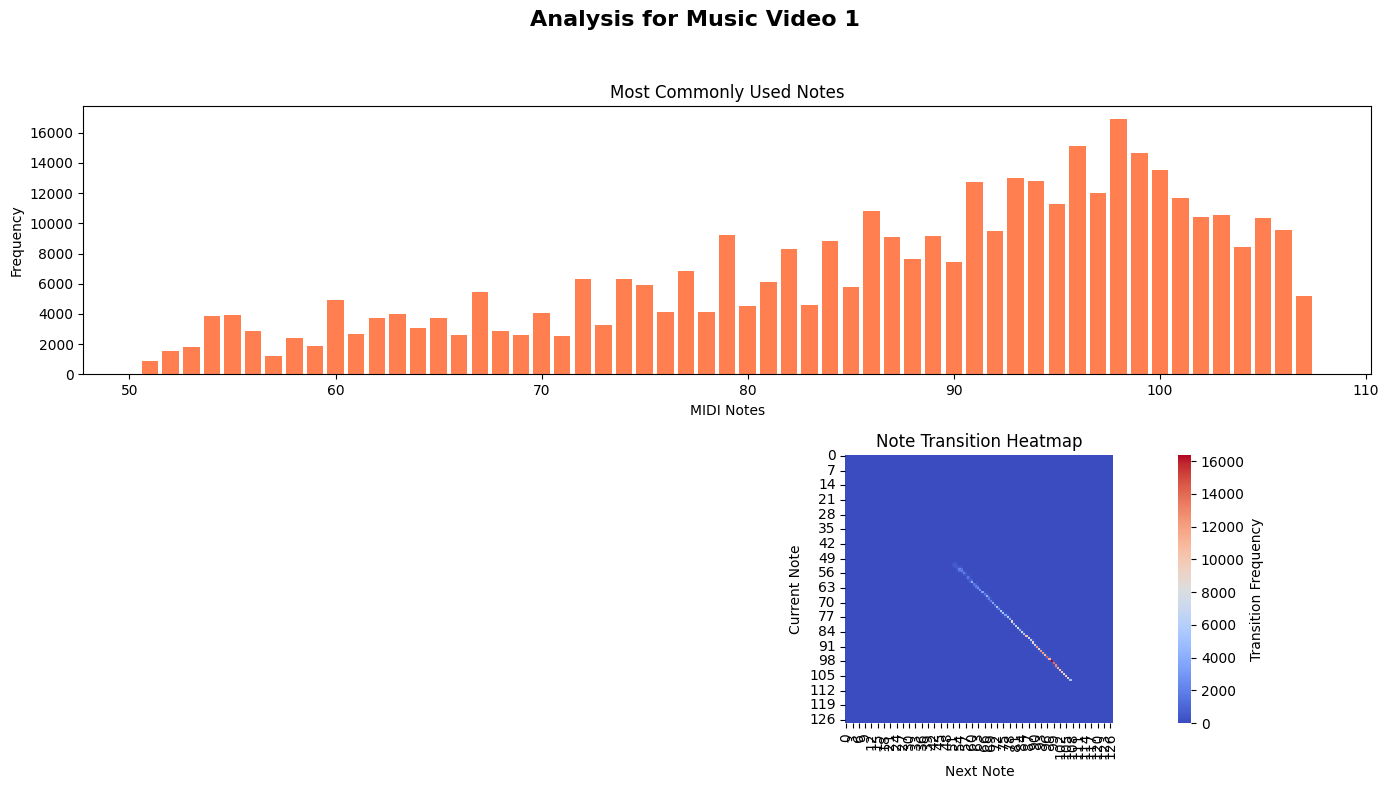

Processing: Freiren_Freiren_-_Sunny.mp3


/usr/local/lib/python3.10/dist-packages/librosa/core/convert.py:1095: RuntimeWarning: divide by zero encountered in log2
  midi: np.ndarray = 12 * (np.log2(np.asanyarray(frequencies)) - np.log2(440.0)) + 69


Creating graphs for Freiren_Freiren_-_Sunny.mp3...


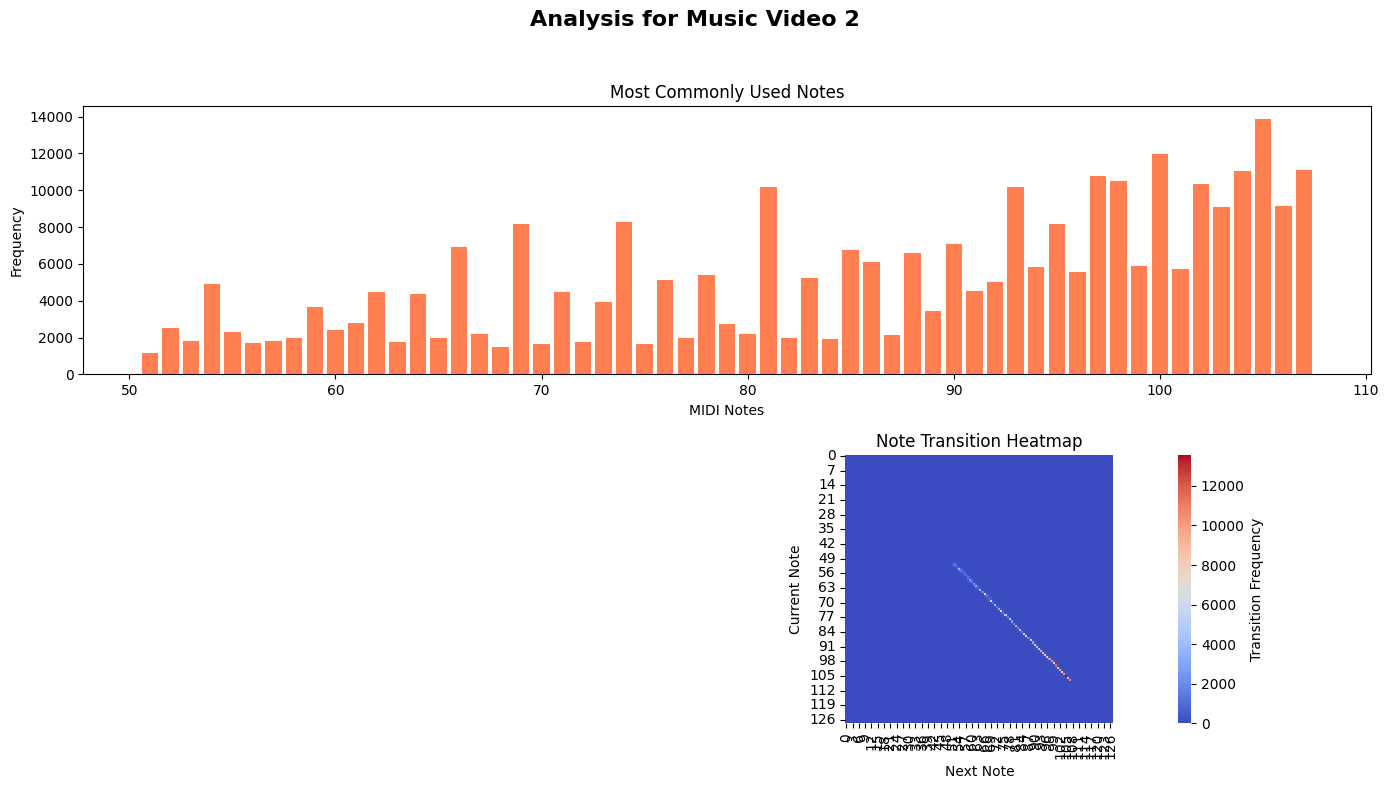

Processing: Jujutsu_Kaisen_Jujutsu_Kaisen_-_SPECIALZ.mp3


/usr/local/lib/python3.10/dist-packages/librosa/core/convert.py:1095: RuntimeWarning: divide by zero encountered in log2
  midi: np.ndarray = 12 * (np.log2(np.asanyarray(frequencies)) - np.log2(440.0)) + 69


Creating graphs for Jujutsu_Kaisen_Jujutsu_Kaisen_-_SPECIALZ.mp3...


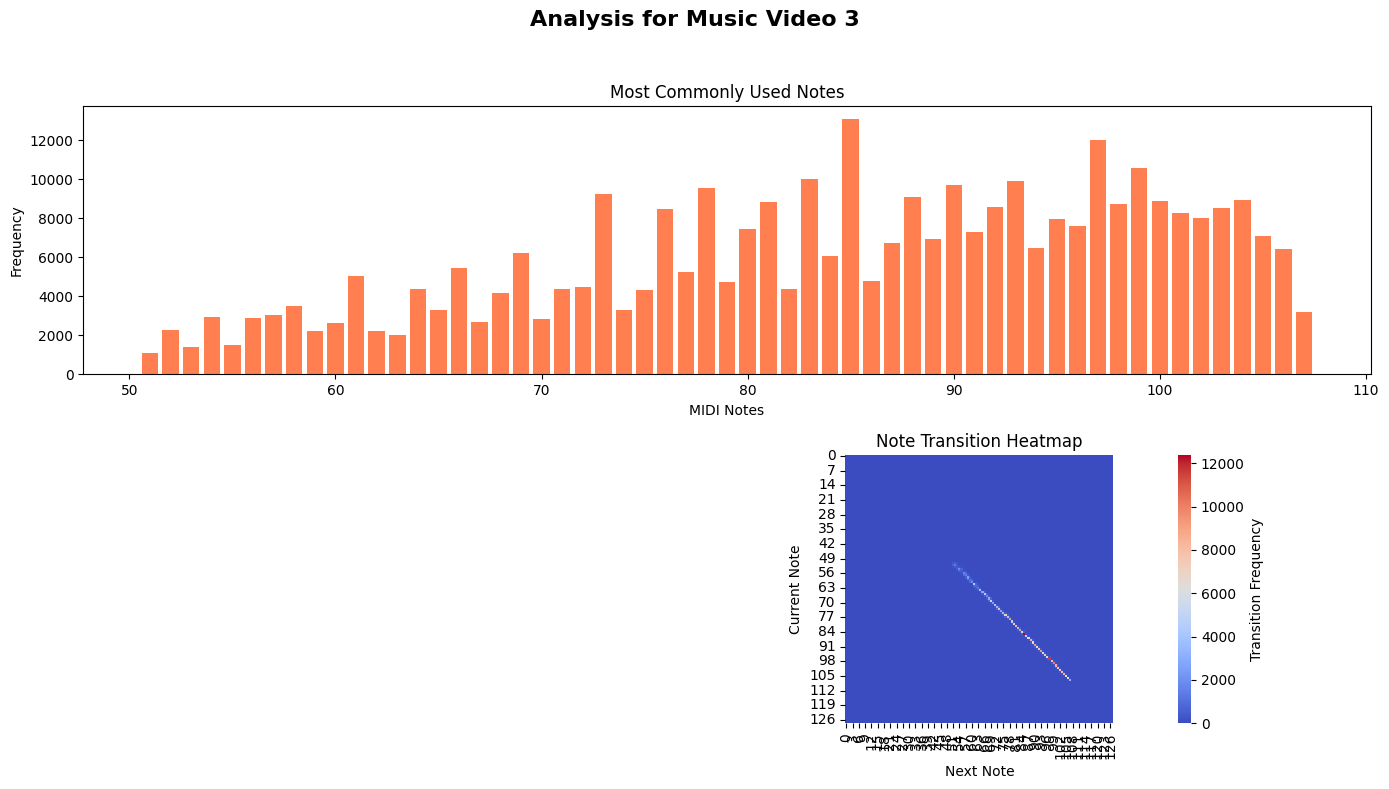

Processing: Tokyo_ghoul_Tokyo_Ghoul_-_unravel.mp3


/usr/local/lib/python3.10/dist-packages/librosa/core/convert.py:1095: RuntimeWarning: divide by zero encountered in log2
  midi: np.ndarray = 12 * (np.log2(np.asanyarray(frequencies)) - np.log2(440.0)) + 69


Creating graphs for Tokyo_ghoul_Tokyo_Ghoul_-_unravel.mp3...


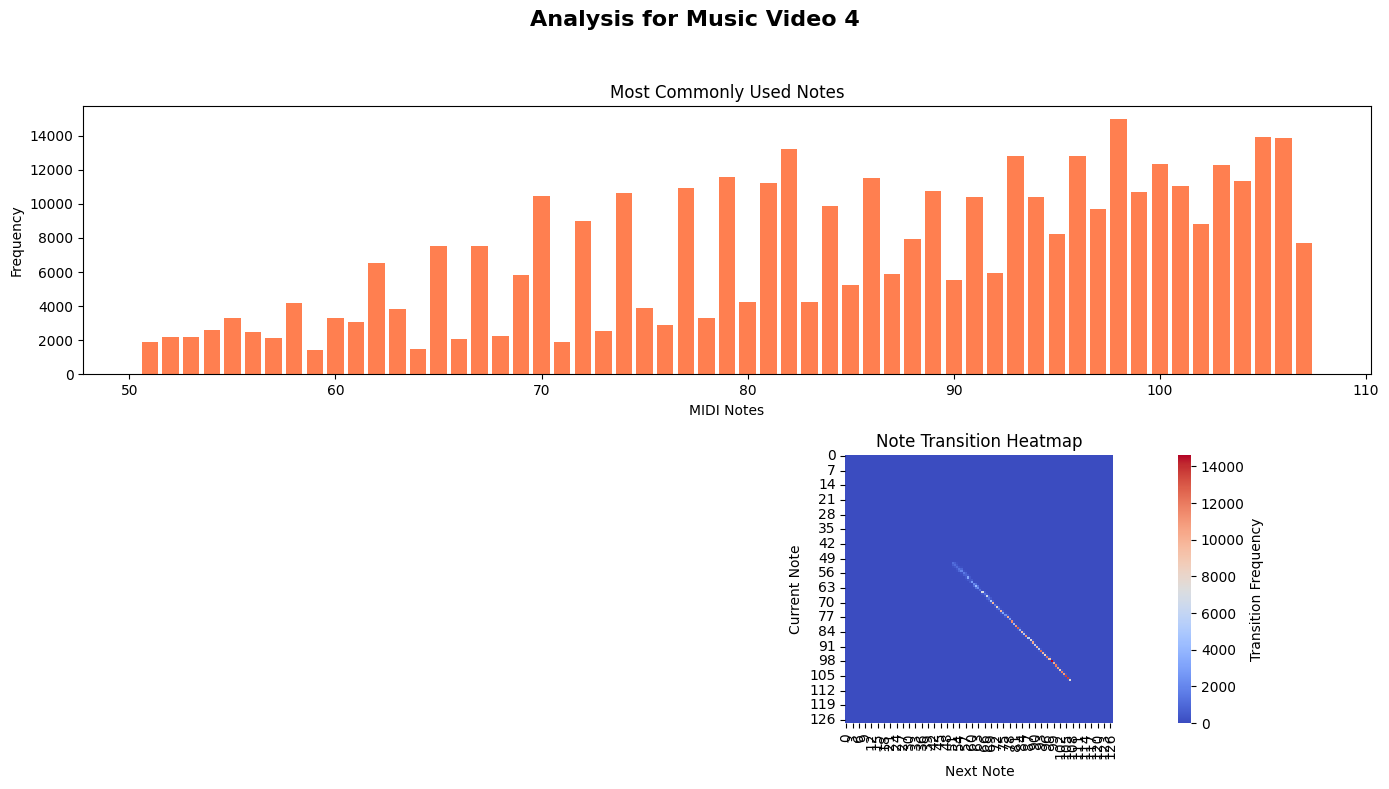

Processing: Violet_Evergarden_Violet_Evergarden_-_Sincerely.mp3


/usr/local/lib/python3.10/dist-packages/librosa/core/convert.py:1095: RuntimeWarning: divide by zero encountered in log2
  midi: np.ndarray = 12 * (np.log2(np.asanyarray(frequencies)) - np.log2(440.0)) + 69


Creating graphs for Violet_Evergarden_Violet_Evergarden_-_Sincerely.mp3...


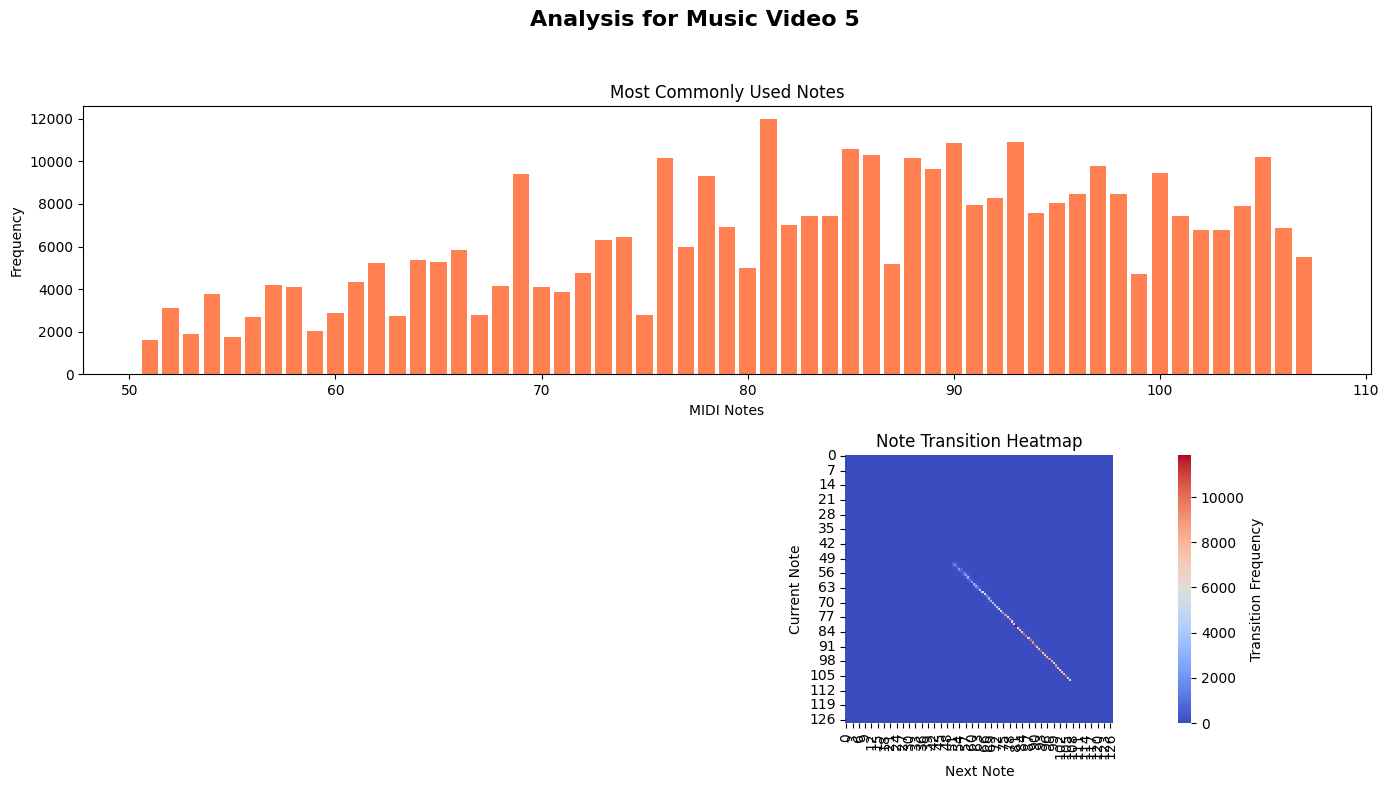

Processing: One_Piece_One_Piece_-_Tot_Musica.mp3


/usr/local/lib/python3.10/dist-packages/librosa/core/convert.py:1095: RuntimeWarning: divide by zero encountered in log2
  midi: np.ndarray = 12 * (np.log2(np.asanyarray(frequencies)) - np.log2(440.0)) + 69


Creating graphs for One_Piece_One_Piece_-_Tot_Musica.mp3...


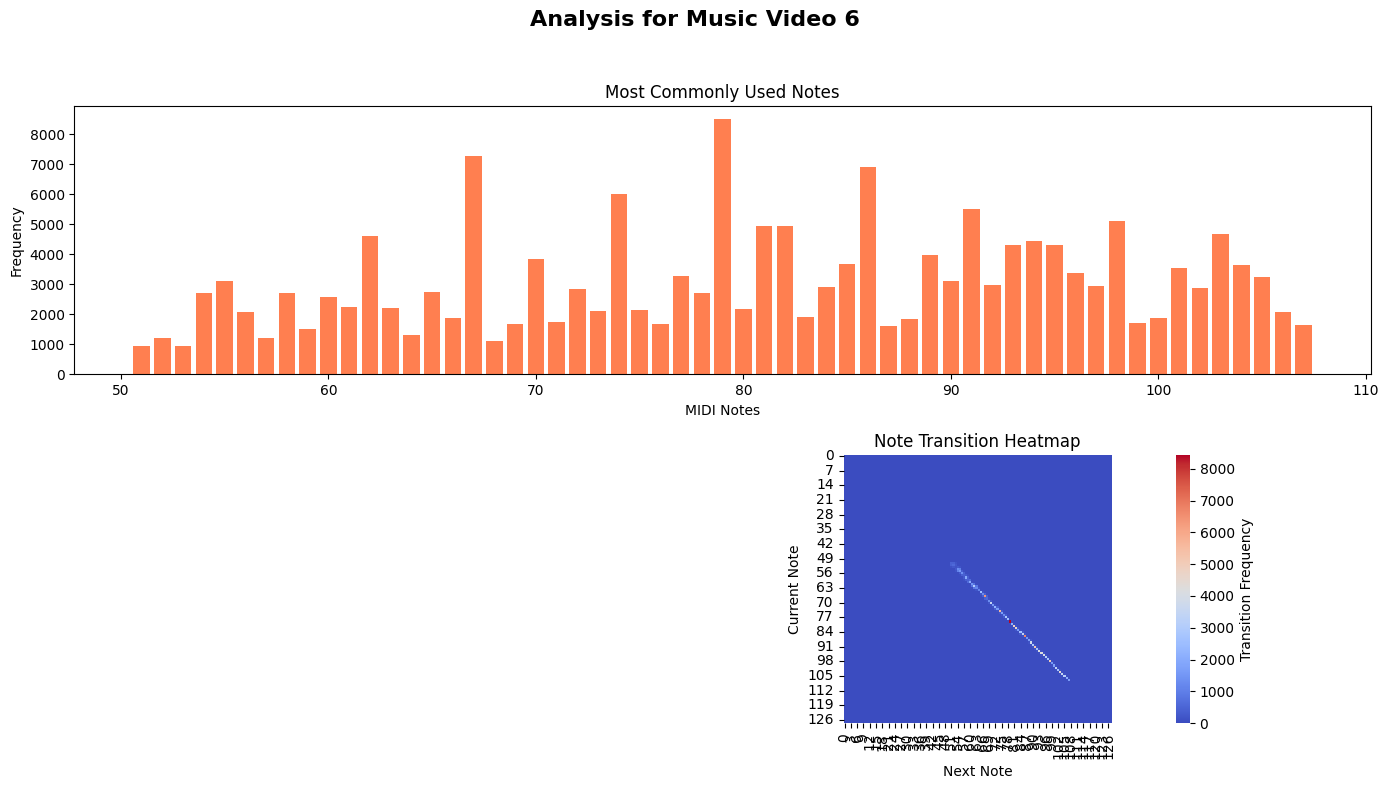

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import subprocess

# Function to download audio using yt-dlp
def download_audio(youtube_url, filename):
    command = [
        "yt-dlp",
        "-x", "--audio-format", "mp3",
        "-o", f"{filename}.mp3",
        youtube_url
    ]
    subprocess.run(command, check=True)

# Function to analyze notes and transitions
def analyze_notes_and_transitions(audio_file):
    # Load audio file
    y, sr = librosa.load(audio_file, sr=None)

    # Extract pitches and magnitudes
    pitches, magnitudes = librosa.piptrack(y=y, sr=sr)

    # Convert pitches to MIDI numbers
    midi_pitches = librosa.hz_to_midi(pitches)

    # Flatten to a 1D array of notes
    note_sequence = np.round(midi_pitches[midi_pitches > 0]).astype(int)

    # Count note frequencies
    unique, counts = np.unique(note_sequence, return_counts=True)
    note_frequencies = dict(zip(unique, counts))

    # Calculate transitions
    transitions = {}
    for i in range(len(note_sequence) - 1):
        pair = (note_sequence[i], note_sequence[i + 1])
        if pair not in transitions:
            transitions[pair] = 0
        transitions[pair] += 1

    return note_frequencies, transitions

# Function to process and plot for multiple videos
def process_and_plot_multiple_videos(audio_files):
    for idx, audio_file in enumerate(audio_files, start=1):
        print(f"Processing: {audio_file}")

        # Analyze notes and transitions
        try:
            note_frequencies, transitions = analyze_notes_and_transitions(audio_file)

            # Create graphs
            print(f"Creating graphs for {audio_file}...")
            plt.figure(figsize=(14, 8))
            plt.suptitle(f"Analysis for Music Video {idx}", fontsize=16, fontweight='bold')

            # Plot note frequencies
            plt.subplot(2, 1, 1)
            notes = list(note_frequencies.keys())
            frequencies = list(note_frequencies.values())
            plt.bar(notes, frequencies, color='coral')
            plt.xlabel("MIDI Notes")
            plt.ylabel("Frequency")
            plt.title("Most Commonly Used Notes")

            # Prepare data for transition heatmap
            plt.subplot(2, 1, 2)
            transition_matrix = np.zeros((128, 128))  # MIDI notes 0-127
            for (note1, note2), count in transitions.items():
                transition_matrix[note1, note2] = count
            sns.heatmap(transition_matrix, cmap='coolwarm', square=True, cbar_kws={'label': 'Transition Frequency'})
            plt.xlabel("Next Note")
            plt.ylabel("Current Note")
            plt.title("Note Transition Heatmap")

            plt.tight_layout(rect=[0, 0, 1, 0.95])
            plt.show()
        except Exception as e:
            print(f"Failed to process {audio_file}: {e}")

# List of additional audio files (replace with your actual file paths)
audio_files = [
    "Attack_on_Titan_Attack_on_Titan_-_The_Rumbling.mp3",  # Replace with the path to your downloaded MP3 files
    "Freiren_Freiren_-_Sunny.mp3",
    "Jujutsu_Kaisen_Jujutsu_Kaisen_-_SPECIALZ.mp3",
    "Tokyo_ghoul_Tokyo_Ghoul_-_unravel.mp3",
    "Violet_Evergarden_Violet_Evergarden_-_Sincerely.mp3",
    "One_Piece_One_Piece_-_Tot_Musica.mp3"
]

# Process and plot for the additional audio files
process_and_plot_multiple_videos(audio_files)


d) Create a 30-second simple audio piece inspired by Japanese anime BGM

In [ ]:
!pip install pydub

In [ ]:
from pydub.generators import Sine
from pydub import AudioSegment

# Define a function to create a tone with specific frequency and duration
def create_tone(frequency, duration, amplitude=0.7):  # Set default amplitude to 1.0 for higher volume
    return Sine(frequency).to_audio_segment(duration=duration, volume=amplitude * 100 - 100)

# Define the main melody (simple arpeggio inspired by anime BGM)
melody = (
    create_tone(880, 400) +  # A5 (higher pitch)
    create_tone(987, 400) +  # B5 (higher pitch)
    create_tone(1046, 400) + # C6 (higher pitch)
    create_tone(1174, 400)   # D6 (higher pitch)
)

# Define the harmony (lower tones for atmosphere)
harmony = (
    create_tone(440, 1600).fade_in(200).fade_out(200) +  # A4 (higher pitch)
    create_tone(392, 1600).fade_in(200).fade_out(200)    # G4 (higher pitch)
)

# Combine melody and harmony by overlaying them
bgm = AudioSegment.silent(duration=0)
while len(bgm) < 30000:  # Loop until the bgm is at least 30 seconds long
    bgm += melody.overlay(harmony)

# Trim the bgm to exactly 30 seconds
bgm = bgm[:30000]

# Export the BGM as a file
bgm.export("anime_bgm.mp3", format="mp3")

print("Anime BGM generated and saved as anime_bgm.mp3")

Anime BGM generated and saved as anime_bgm.mp3
